In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.db_connector import get_connection

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

conn = get_connection()
# Load sample of raw anomalies for direct visualization
raw_sample_query = """
SELECT invoice, stock_code, quantity, price, invoice_date, customer_id
FROM raw_retail_transactions
LIMIT 200000;
"""
df_raw = pd.read_sql(raw_sample_query, conn)
conn.close()

print(f"Sample loaded: {df_raw.shape}")

C:\Users\lenov\AppData\Local\Temp\ipykernel_14048\654843829.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_raw = pd.read_sql(raw_sample_query, conn)


Sample loaded: (200000, 6)


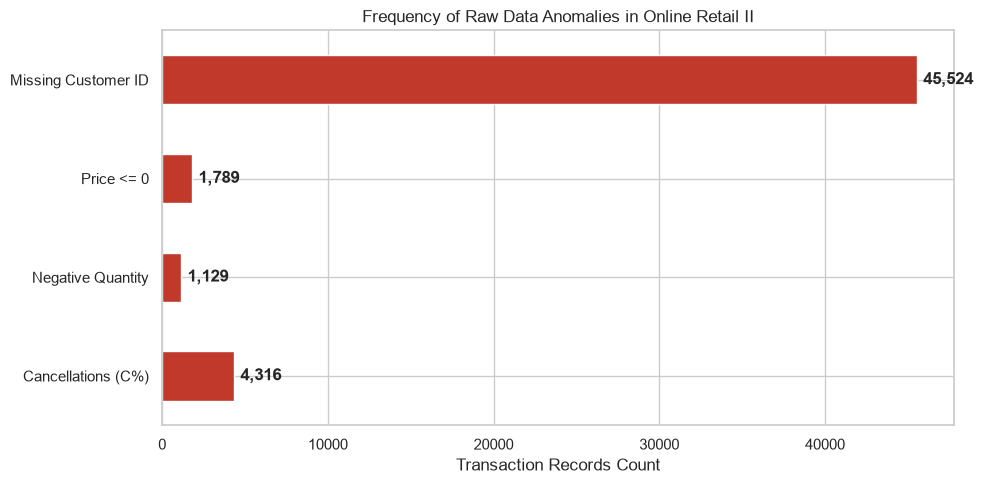

In [2]:
# Segment transactions into categorical flags
df_raw["is_cancellation"] = df_raw["invoice"].str.startswith("C", na=False)
df_raw["is_negative_qty"] = df_raw["quantity"] < 0
df_raw["is_non_positive_price"] = df_raw["price"] <= 0
df_raw["is_missing_customer"] = df_raw["customer_id"].isna() | (
    df_raw["customer_id"] == ""
)

anomaly_breakdown = pd.Series(
    {
        "Cancellations (C%)": df_raw["is_cancellation"].sum(),
        "Negative Quantity": (
            df_raw["is_negative_qty"] & ~df_raw["is_cancellation"]
        ).sum(),
        "Price <= 0": df_raw["is_non_positive_price"].sum(),
        "Missing Customer ID": df_raw["is_missing_customer"].sum(),
    }
)

fig, ax = plt.subplots()
anomaly_breakdown.plot(kind="barh", color="#c0392b", ax=ax)
ax.set_title("Frequency of Raw Data Anomalies in Online Retail II")
ax.set_xlabel("Transaction Records Count")
for i, v in enumerate(anomaly_breakdown):
    ax.text(v + 100, i, f" {v:,}", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

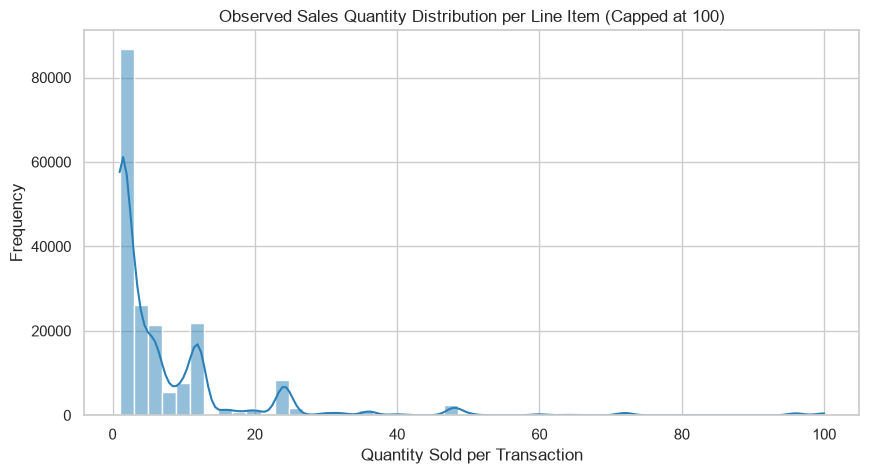

In [3]:
# Filtering clean positives to inspect natural skewness
clean_quantities = df_raw.loc[
    (df_raw["quantity"] > 0)
    & (df_raw["quantity"] <= 100)
    & (df_raw["price"] > 0),
    "quantity",
]

fig, ax = plt.subplots()
sns.histplot(clean_quantities, bins=50, kde=True, color="#2980b9", ax=ax)
ax.set_title(
    "Observed Sales Quantity Distribution per Line Item (Capped at 100)"
)
ax.set_xlabel("Quantity Sold per Transaction")
ax.set_ylabel("Frequency")
plt.show()

In [4]:
import numpy as np
import pandas as pd

# Profile the loaded staging transactions
raw = df_raw.copy()
n_raw = len(raw)

# Identify invalid transactions and accounting adjustments
is_cancelled = raw["invoice"].astype(str).str.startswith("C", na=False)
is_bad_qty = raw["quantity"] <= 0
is_bad_price = raw["price"] <= 0
is_anon_cust = (
    raw["customer_id"].isna() | (raw["customer_id"].astype(str).str.strip() == "")
)

# Administrative and non-inventory line items
admin_codes = [
    "POST", "D", "M", "BANK CHARGES", "AMAZONFEE",
    "CRUK", "TEST", "PADS", "ADJUST", "ADJUST2"
]
is_admin = raw["stock_code"].astype(str).str.upper().str.strip().isin(admin_codes)

# Extract clean physical sales slice
clean_mask = ~is_cancelled & ~is_bad_qty & ~is_bad_price & ~is_admin
clean = raw[clean_mask].copy()

# Summary statistics for verified inventory movement
q = clean["quantity"]
p = clean["price"]

# Compile metric tables
raw_metrics = pd.DataFrame([
    {"Metric": "Total Raw Rows", "Value": f"{n_raw:,}"},
    {"Metric": "Unique Invoices", "Value": f"{raw['invoice'].nunique():,}"},
    {"Metric": "Unique SKUs", "Value": f"{raw['stock_code'].nunique():,}"},
    {"Metric": "Start Date", "Value": str(pd.to_datetime(raw["invoice_date"]).min())},
    {"Metric": "End Date", "Value": str(pd.to_datetime(raw["invoice_date"]).max())},
])

anomaly_metrics = pd.DataFrame([
    {"Anomaly Type": "Cancellations (C%)", "Count": f"{int(is_cancelled.sum()):,}", "Share (%)": f"{(is_cancelled.sum() / n_raw) * 100:.2f}%"},
    {"Anomaly Type": "Unlinked Negative Quantity", "Count": f"{int((is_bad_qty & ~is_cancelled).sum()):,}", "Share (%)": f"{((is_bad_qty & ~is_cancelled).sum() / n_raw) * 100:.2f}%"},
    {"Anomaly Type": "Zero / Negative Unit Price", "Count": f"{int(is_bad_price.sum()):,}", "Share (%)": f"{(is_bad_price.sum() / n_raw) * 100:.2f}%"},
    {"Anomaly Type": "Administrative Line Items", "Count": f"{int(is_admin.sum()):,}", "Share (%)": f"{(is_admin.sum() / n_raw) * 100:.2f}%"},
    {"Anomaly Type": "Missing Customer IDs (Retained)", "Count": f"{int(is_anon_cust.sum()):,}", "Share (%)": f"{(is_anon_cust.sum() / n_raw) * 100:.2f}%"},
])

retention_metrics = pd.DataFrame([
    {"Metric": "Clean Rows Retained", "Value": f"{len(clean):,}"},
    {"Metric": "Retention Rate", "Value": f"{(len(clean) / n_raw) * 100:.2f}%"},
    {"Metric": "Unique Clean Invoices", "Value": f"{clean['invoice'].nunique():,}"},
    {"Metric": "Unique Clean SKUs", "Value": f"{clean['stock_code'].nunique():,}"},
])

percentiles = [0.25, 0.50, 0.75, 0.95, 0.99]
display(clean[["quantity", "price"]].describe(percentiles=percentiles).round(2))

# Display findings directly
print("--- 1. RAW INGESTION SCOPE ---")
display(raw_metrics)

print("\n--- 2. DETECTED ANOMALIES & LEDGER ARTIFACTS ---")
display(anomaly_metrics)

print("\n--- 3. CLEAN RETENTION SUMMARY ---")
display(retention_metrics)

print("\n--- 4. CLEAN QUANTITY & PRICE DISTRIBUTIONS ---")
percentiles = [0.25, 0.50, 0.75, 0.95, 0.99]
display(clean[["quantity", "price"]].describe(percentiles=percentiles).round(2))

,quantity,price
count,193339.00,193339.00
mean,11.95,3.81
std,112.57,11.88
min,1.00,0.04
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.25
95%,32.00,10.75
99%,120.00,18.95
max,19152.00,1157.15


--- 1. RAW INGESTION SCOPE ---


,Metric,Value
0,Total Raw Rows,"200,000"
1,Unique Invoices,"11,456"
2,Unique SKUs,"4,123"
3,Start Date,2009-12-01 07:45:00
4,End Date,2010-05-17 13:18:00



--- 2. DETECTED ANOMALIES & LEDGER ARTIFACTS ---


,Anomaly Type,Count,Share (%)
0,Cancellations (C%),"4,316",2.16%
1,Unlinked Negative Quantity,"1,129",0.56%
2,Zero / Negative Unit Price,"1,789",0.89%
3,Administrative Line Items,795,0.40%
4,Missing Customer IDs (Retained),"45,524",22.76%



--- 3. CLEAN RETENTION SUMMARY ---


,Metric,Value
0,Clean Rows Retained,"193,339"
1,Retention Rate,96.67%
2,Unique Clean Invoices,"7,762"
3,Unique Clean SKUs,"3,739"



--- 4. CLEAN QUANTITY & PRICE DISTRIBUTIONS ---


,quantity,price
count,193339.00,193339.00
mean,11.95,3.81
std,112.57,11.88
min,1.00,0.04
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.25
95%,32.00,10.75
99%,120.00,18.95
max,19152.00,1157.15



# Data Quality & Sanity Check Notes (Notebook 02)

## Quick Context on What We're Looking At
Before running full-scale transformations across the whole database, I pulled a diagnostic batch of 200k raw rows from the MySQL staging table (`raw_retail_transactions`) to inspect what the data actually looks like and spot any weird ledger quirks early on.

* **Raw rows pulled:** 200,000 line items
* **Unique invoices in batch:** 11,456
* **Unique stock codes:** 4,123
* **Date range:** Dec 1, 2009 up to mid May 2010

---

## Messy Records & Edge Cases Spotted

Here is what came up when looking for broken records, manual adjustments, and missing fields:

| Issue | Filter / Logic | Count | % of batch | What it actually means & what we did with it |
| :--- | :--- | :---: | :---: | :--- |
| **Cancellations** | Starts with 'C' in invoice | 4,316 | ~2.16% | Customer returns or cancelled orders. **Dropped.** They don't link back cleanly to the original purchase date in this dataset. |
| **Random negative qty** | `quantity <= 0` (no 'C' prefix) | 1,129 | ~0.56% | Warehouse breakages, inventory adjustments, or system write-offs. **Dropped.** |
| **Zero or negative price** | `price <= 0` | 1,789 | ~0.89% | Free samples, internal testing, or weird ledger corrections. **Dropped.** |
| **Admin codes** | Stock codes like `POST`, `D`, `M`, etc. | 795 | ~0.40% | Non-product line items like postage fees, bank charges, and manual discounts. **Dropped.** |
| **Missing Customer IDs** | Blank or NaN customer field | 45,524 | 22.76% | Guest checkouts or wholesale walk-ins. **Kept.** |

---

## Engineering Decisions & Trade-offs

### 1. Dropping returns instead of subtracting them
* **The issue:** Returns in this dataset are recorded as negative quantities on the day the refund was issued—sometimes weeks or months after the goods actually shipped.
* **Why not subtract?** If you net them out on the return date, you end up creating artificial negative demand spikes on random days in the future, which introduces lookahead leakage into a forecasting model.
* **Our call:** We dropped all `C%` records here. The goal of this pipeline is forecasting outward warehouse demand (units leaving the loading dock). Returns handling is better treated as a separate reverse-logistics or accounting problem.

### 2. Not tossing out missing `customer_id` records
* **The trap:** A lot of standard EDA scripts just run `.dropna(subset=['customer_id'])`.
* **The issue:** Doing that here would throw away **almost 23% of total sales volume**.
* **Our call:** We kept all of them. For demand forecasting, all that matters is whether inventory left the warehouse. It doesn't matter whether the buyer logged in or checked out anonymously.

### 3. Cleaning out non-inventory codes
* Found codes like `POST` (postage), `D` (discounts), `M` (manual entry), and `BANK CHARGES` sitting inside the product column.
* Dropped these so our feature engineering step only tracks actual physical items.

---

## Clean Slice Retention


```

Raw batch: 200,000 rows (4,123 SKUs)
│
├── Drop cancellations: -4,316
├── Drop negative qty: -1,129
├── Drop <= 0 prices: -1,789
└── Drop admin codes: -795
│
▼
Clean sales rows: 193,339 rows (~96.7% kept)
Active invoices left: 7,762
Valid physical SKUs left: 3,739

```

About 3.3% of the raw rows were tossed due to overlapping filters. We also shaved off roughly 384 non-product or broken stock codes.

---

## Distribution Check (`df.describe()`)

Running `.describe()` on the cleaned subset gives a clear picture of why simple linear models struggle here:

| Metric | Quantity Sold | Price (£) |
| :--- | :---: | :---: |
| **Mean** | 11.95 | 3.81 |
| **Std** | 112.57 | 11.88 |
| **Min** | 1 | 0.04 |
| **25%** | 1 | 1.25 |
| **50% (Median)** | 3 | 2.10 |
| **75%** | 10 | 4.25 |
| **95%** | 32 | 10.75 |
| **99%** | 120 | 18.95 |
| **Max** | 19,152 | 1,157.15 |

### Takeaways for modeling:
* **Heavy right tail on quantity:** The median is only 3 units, and 75% of purchases are 10 units or less, but the max is over 19,000. There are massive periodic wholesale orders scattered throughout. This means we'll definitely need a log transform like $\log(1 + y)$ and robust loss functions (like L1 or Huber) so large bulk orders don't break our tree splits.
* **Unit pricing:** Prices are mostly low (median £2.10), but there are high-value items pulling the mean up. In our daily aggregation step, we should calculate volume-weighted average price ($\frac{\sum \text{Revenue}}{\sum \text{Qty}}$) rather than a simple arithmetic average so bulk discounts don't get distorted.

```